<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/Resnet50/notebooks/ResNet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import sys
import json
import hashlib
import time
import random
import platform
import shutil
import subprocess
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import sklearn
import kagglehub
import matplotlib
import matplotlib.pyplot as plt

# Architecture-specific preprocessor for ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess_input

print("All imports completed successfully.")

All imports completed successfully.


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    determinism_status = "TensorFlow op determinism enabled"
except Exception as e:
    determinism_status = f"Could not enable op determinism: {e}"

print(f"Seed:        {SEED}")
print(f"Determinism: {determinism_status}")

Seed:        42
Determinism: TensorFlow op determinism enabled


In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        gpu_name = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
        nvidia_smi = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
    except Exception:
        gpu_name = tf.config.experimental.get_device_details(gpus[0]).get('device_name', 'Unknown GPU')
        nvidia_smi = 'Unavailable'
else:
    gpu_name = 'No GPU detected'
    nvidia_smi = 'N/A'

environment_info = {
    'member': 3,
    'model': 'ResNet50',
    'python_version': sys.version,
    'platform': platform.platform(),
    'tensorflow_version': tf.__version__,
    'keras_version': keras.__version__,
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'scikit_learn_version': sklearn.__version__,
    'kagglehub_version': getattr(kagglehub, '__version__', 'unknown'),
    'matplotlib_version': matplotlib.__version__,
    'gpu_name': gpu_name,
    'nvidia_smi': nvidia_smi,
    'seed': SEED,
    'determinism_status': determinism_status,
}

print('Environment Recorded:')
for k, v in environment_info.items():
    print(f'  {k:<22}: {v}')

Environment Recorded:
  member                : 3
  model                 : ResNet50
  python_version        : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
  platform              : Linux-6.6.122+-x86_64-with-glibc2.39
  tensorflow_version    : 2.21.0
  keras_version         : 3.13.2
  numpy_version         : 2.1.3
  pandas_version        : 2.2.3
  scikit_learn_version  : 1.6.1
  kagglehub_version     : 1.0.2
  matplotlib_version    : 3.10.0
  gpu_name              : No GPU detected
  nvidia_smi            : N/A
  seed                  : 42
  determinism_status    : TensorFlow op determinism enabled


In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Dataset")
DATA_DIR = Path("/content/drive/MyDrive/Dataset")
SPLITS_DIR = PROJECT_DIR / "data" / "splits"
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = RESULTS_DIR / "plots"
METRICS_DIR = RESULTS_DIR / "metrics"
MODELS_DIR = PROJECT_DIR / "models"
FINAL_MODEL_DIR = MODELS_DIR / "final"
CHECKPOINT_DIR = MODELS_DIR / "checkpoints"

for folder in [
    SPLITS_DIR, PLOTS_DIR, METRICS_DIR, FINAL_MODEL_DIR, CHECKPOINT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Scan the dataset (`correct` / `wrong`)

Expected layout (inside `DATA_DIR`):
```
raw/
  correct/  img1.jpg, img2.png, ...
  wrong/    img1.jpg, ...
```
This cell lists every image, checks that it opens, removes exact duplicates (so the same image can't end up in both train and test), and builds a table of `path / label / class`.

In [ ]:
import io
from PIL import Image

# Image settings
IMG_HEIGHT = 224          # ResNet50 standard input size
IMG_WIDTH  = 224
BATCH_SIZE = 32

CLASS_NAMES = ["Correct", "Wrong"]            # folder names -> labels 0 and 1
IMAGE_EXTS  = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(f"DATA_DIR not found: {DATA_DIR}  -> check the path in the paths cell")

rows, corrupt = [], []
for label, cls in enumerate(CLASS_NAMES):
    cls_dir = DATA_DIR / cls
    if not cls_dir.is_dir():
        raise FileNotFoundError(
            f"Missing folder: {cls_dir}\nFolders found in DATA_DIR: {[p.name for p in DATA_DIR.iterdir()]}"
        )
    for p in sorted(cls_dir.rglob("*")):
        if p.suffix.lower() not in IMAGE_EXTS:
            continue
        try:
            data = p.read_bytes()
            Image.open(io.BytesIO(data)).verify()          # raises if the file is broken
            rows.append({"path": str(p), "label": label, "class": cls,
                         "md5": hashlib.md5(data).hexdigest()})
        except Exception as e:
            corrupt.append((str(p), str(e)))

df = pd.DataFrame(rows)
print(f"Valid images found : {len(df)}")
print(f"Corrupt/unreadable : {len(corrupt)}")
for path, err in corrupt[:5]:
    print("   ", path, "->", err)

# Same image present in BOTH folders = conflicting label -> remove all copies
n_labels_per_hash = df.groupby("md5")["label"].nunique()
conflict_hashes = n_labels_per_hash[n_labels_per_hash > 1].index
if len(conflict_hashes):
    print(f"WARNING: {len(conflict_hashes)} image(s) appear in both correct and wrong -> removed")
    df = df[~df["md5"].isin(conflict_hashes)]

# Exact duplicates inside the same class -> keep one copy
n_before = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Exact duplicates removed: {n_before - len(df)}")

print("\nImages per class:")
print(df["class"].value_counts().to_string())

Valid images found : 1002
Corrupt/unreadable : 0
Exact duplicates removed: 3

Images per class:
class
Wrong      554
Correct    445


## 2. Train / validation / test split (70 / 15 / 15, stratified)

The split is saved as CSV files so every experiment (and every team member) uses exactly the same images.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part.to_csv(SPLITS_DIR / f"{name}.csv", index=False)
    counts = part["class"].value_counts().to_dict()
    print(f"{name:<5}: {len(part):>5} images  {counts}")

train:   699 images  {'Wrong': 388, 'Correct': 311}
val  :   150 images  {'Wrong': 83, 'Correct': 67}
test :   150 images  {'Wrong': 83, 'Correct': 67}


## 3. Preprocessing: same size + pure black & white

Steps for every image:
1. Decode (works for JPG / PNG / BMP)
2. Convert to grayscale
3. Pick a threshold (Otsu = automatic per image, or a fixed value)
4. Resize to 224x224 **keeping the aspect ratio** (the letter shape is not stretched; padding is white)
5. Threshold into pure black (0) and white (255)
6. Copy the 1 channel into 3 channels and apply ResNet50 `preprocess_input`

The black/white result is cached in memory (uint8, 1 channel) so only the first epoch reads from Drive.

In [ ]:
USE_OTSU        = True     # True: automatic threshold per image | False: use FIXED_THRESHOLD
FIXED_THRESHOLD = 127.0

def otsu_threshold(gray):
    """gray: float32 tensor with values 0-255. Returns Otsu's threshold as a scalar."""
    hist  = tf.cast(tf.histogram_fixed_width(gray, [0.0, 256.0], nbins=256), tf.float32)
    bins  = tf.range(256, dtype=tf.float32)
    w_bg  = tf.cumsum(hist)                         # pixels at or below each level
    w_fg  = tf.reduce_sum(hist) - w_bg              # pixels above each level
    s_all = tf.reduce_sum(hist * bins)
    s_bg  = tf.cumsum(hist * bins)
    m_bg  = s_bg / tf.maximum(w_bg, 1.0)
    m_fg  = (s_all - s_bg) / tf.maximum(w_fg, 1.0)
    between_class_variance = w_bg * w_fg * tf.square(m_bg - m_fg)
    return tf.cast(tf.argmax(between_class_variance), tf.float32)

def load_and_binarize(file_path):
    """Image path -> uint8 tensor [224, 224, 1] containing only 0 (black) and 255 (white)."""
    img = tf.io.decode_image(tf.io.read_file(file_path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])

    gray = tf.image.rgb_to_grayscale(tf.cast(img, tf.float32))        # [H, W, 1], 0-255
    thr  = otsu_threshold(gray) if USE_OTSU else FIXED_THRESHOLD       # threshold from the original image

    # Resize with aspect ratio kept. resize_with_pad pads with 0, so invert -> resize -> invert back
    # to make the padding white instead of black.
    inverted = 255.0 - gray
    inverted = tf.image.resize_with_pad(inverted, IMG_HEIGHT, IMG_WIDTH, antialias=True)
    gray     = 255.0 - inverted

    bw = tf.where(gray > thr, 255.0, 0.0)                              # pure black & white
    return tf.cast(bw, tf.uint8)

def to_resnet_input(bw, label):
    """[224, 224, 1] uint8 B&W -> [224, 224, 3] float32 in ResNet50's expected input format."""
    x = tf.tile(tf.cast(bw, tf.float32), [1, 1, 3])
    return resnet50_preprocess_input(x), label

def make_dataset(df_part, training):
    paths  = df_part["path"].tolist()
    labels = df_part["label"].astype("int32").tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(lambda p, y: (load_and_binarize(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()                                   # keep the small B&W images in RAM after epoch 1
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(to_resnet_input, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

## 4. Visual check

Look at a few results before training. Letters should be clearly black on white, not broken or filled in. If they look wrong, try `USE_OTSU = False` and change `FIXED_THRESHOLD`.

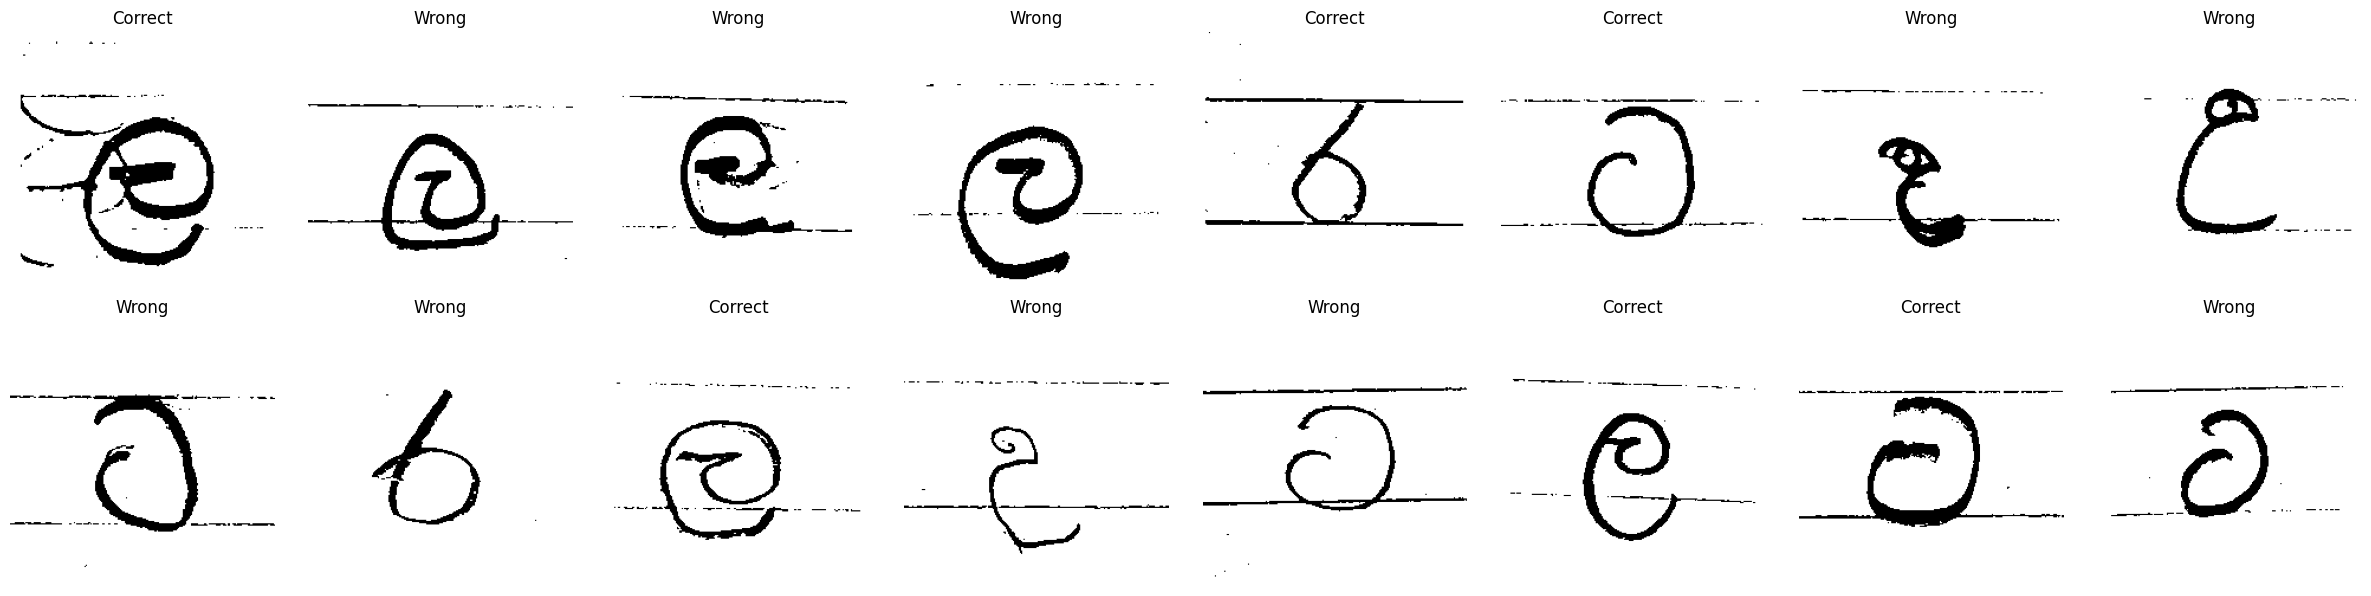

In [ ]:
def show_samples(df_part, n=16):
    n = min(n, len(df_part))
    sample = df_part.sample(n, random_state=SEED)
    cols = max(n // 2, 1)
    fig, axes = plt.subplots(2, cols, figsize=(3 * cols, 6))
    for ax, (_, r) in zip(np.ravel(axes), sample.iterrows()):
        bw = load_and_binarize(r["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(r["class"])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_df)

## 5. Build the datasets

In [ ]:
train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

# Sanity check on one batch
x, y = next(iter(train_ds))
print("Batch images :", x.shape, x.dtype)
print("Batch labels :", y.shape, y.dtype)
print(f"Value range  : {float(tf.reduce_min(x)):.1f} to {float(tf.reduce_max(x)):.1f}")

# Class weights (helps if one class has far fewer images)
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"].values)
class_weight = {0: float(w[0]), 1: float(w[1])}
print("Class weights:", class_weight, "| labels:", dict(enumerate(CLASS_NAMES)))

Batch images : (32, 224, 224, 3) <dtype: 'float32'>
Batch labels : (32,) <dtype: 'int32'>
Value range  : -123.7 to 151.1
Class weights: {0: 1.1237942122186495, 1: 0.9007731958762887} | labels: {0: 'Correct', 1: 'Wrong'}


## 6. Build the ResNet50 model

Paste these cells **below your last cell** (they use `train_ds`, `val_ds`, `class_weight`, `CLASS_NAMES`, `CHECKPOINT_DIR`, `FINAL_MODEL_DIR`, `METRICS_DIR`, `PLOTS_DIR` from the earlier cells).

Before running: Runtime → Change runtime type → **T4 GPU**.

Plan (standard transfer learning):
1. **Stage 1:** ResNet50 pretrained on ImageNet is frozen, only the new classifier head is trained.
2. **Stage 2:** the last layers of ResNet50 are unfrozen and fine-tuned with a very small learning rate.

The model outputs one number: the probability of **class 1** (`CLASS_NAMES[1]`, which is `Wrong`). Precision and recall below are therefore for the `Wrong` class.

In [ ]:
from tensorflow.keras import layers, models, optimizers, callbacks, metrics

gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - switch the runtime to a T4 GPU, training on CPU is extremely slow")

# ---------------- Model / training settings ----------------
WEIGHTS          = "imagenet"   # pretrained weights
DROPOUT          = 0.3
USE_AUGMENTATION = False        # light shift/zoom only (no flips, no rotation: they can change a letter's meaning)

EPOCHS_HEAD      = 15           # stage 1 (early stopping may end it sooner)
EPOCHS_FINE      = 30           # stage 2 (early stopping may end it sooner)
LR_HEAD          = 1e-3
LR_FINE          = 1e-5
UNFREEZE_LAST_N  = 40           # how many of ResNet50's last layers to fine-tune in stage 2

GPUs: NONE - switch the runtime to a T4 GPU, training on CPU is extremely slow


In [ ]:
def build_resnet50(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), dropout=DROPOUT, augment=USE_AUGMENTATION):
    # include_top=False removes the 1000-class ImageNet classifier, we add our own head
    base = tf.keras.applications.ResNet50(
        include_top=False, weights=WEIGHTS, input_shape=input_shape)
    base.trainable = False                       # stage 1: backbone frozen

    inputs = layers.Input(shape=input_shape, name="image")   # already ResNet50-preprocessed by the data pipeline
    x = inputs
    if augment:
        x = layers.RandomTranslation(0.05, 0.05, fill_mode="nearest")(x)
        x = layers.RandomZoom(0.05, fill_mode="nearest")(x)

    x = base(x, training=False)                  # keeps BatchNorm in inference mode (important for fine-tuning)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prob_class_1")(x)

    model = models.Model(inputs, outputs, name="resnet50_binary")
    return model, base


def compile_model(model, lr):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            metrics.Precision(name="precision"),   # for class 1
            metrics.Recall(name="recall"),         # for class 1
            metrics.AUC(name="auc"),
        ],
    )


def make_callbacks(stage):
    return [
        callbacks.ModelCheckpoint(
            str(CHECKPOINT_DIR / f"resnet50_{stage}_best.keras"),
            monitor="val_loss", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]


def count_params(model):
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    total = int(model.count_params())
    return trainable, total


model, base = build_resnet50()
compile_model(model, LR_HEAD)

trainable, total = count_params(model)
print(f"Stage 1 | trainable params: {trainable:,} of {total:,}")
print(f"Positive class (output = 1): {CLASS_NAMES[1]}")
model.summary(show_trainable=True)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Stage 1 | trainable params: 2,049 of 23,589,761
Positive class (output = 1): Wrong


Model: "resnet50_binary"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ prob_class_1 (Dense)        │ (None, 1)             │      2,049 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 7. Stage 1 - train the classifier head (ResNet50 frozen)

In [ ]:
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=make_callbacks("head"),
)

Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5133 - auc: 0.5513 - loss: 0.8578 - precision: 0.5639 - recall: 0.5601
Epoch 1: val_loss improved from None to 0.85679, saving model to /content/drive/MyDrive/Dataset/models/checkpoints/resnet50_head_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Dataset/models/checkpoints/resnet50_head_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 106s 5s/step - accuracy: 0.5107 - auc: 0.5173 - loss: 0.8672 - precision: 0.5581 - recall: 0.5696 - val_accuracy: 0.4867 - val_auc: 0.5851 - val_loss: 0.8568 - val_precision: 0.7143 - val_recall: 0.1205 - learning_rate: 0.0010
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5214 - auc: 0.5693 - loss: 0.8445 - precision: 0.6367 - recall: 0.3533
Epoch 2: val_loss improved from 0.85679 to 0.68726, saving model to /content/drive/MyDrive/Dataset/models/checkpoints/resnet50_head_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Dataset/models/checkpoints/

## 8. Stage 2 - fine-tune the last ResNet50 layers

Only the last `UNFREEZE_LAST_N` layers are unfrozen. BatchNorm layers stay frozen, and the learning rate is 100x smaller so the pretrained features are adjusted gently instead of destroyed.

In [ ]:
base.trainable = True
for layer in base.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_FINE)          # must re-compile after changing trainable flags

trainable, total = count_params(model)
print(f"Stage 2 | trainable params: {trainable:,} of {total:,}")

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    class_weight=class_weight,
    callbacks=make_callbacks("finetune"),
)

Stage 2 | trainable params: 15,808,769 of 23,589,761
Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6472 - auc: 0.7092 - loss: 0.6334 - precision: 0.7025 - recall: 0.6117
Epoch 1: val_loss improved from None to 0.66402, saving model to /content/drive/MyDrive/Dataset/models/checkpoints/resnet50_finetune_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Dataset/models/checkpoints/resnet50_finetune_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 190s 8s/step - accuracy: 0.6652 - auc: 0.7224 - loss: 0.6222 - precision: 0.7188 - recall: 0.6521 - val_accuracy: 0.6200 - val_auc: 0.6738 - val_loss: 0.6640 - val_precision: 0.6912 - val_recall: 0.5663 - learning_rate: 1.0000e-05
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7048 - auc: 0.7788 - loss: 0.5564 - precision: 0.7521 - recall: 0.7162
Epoch 2: val_loss improved from 0.66402 to 0.66028, saving model to /content/drive/MyDrive/Dataset/models/checkpoints/resnet50_finetune_best.keras

Epoch 2: finish

## 9. Training curves + save

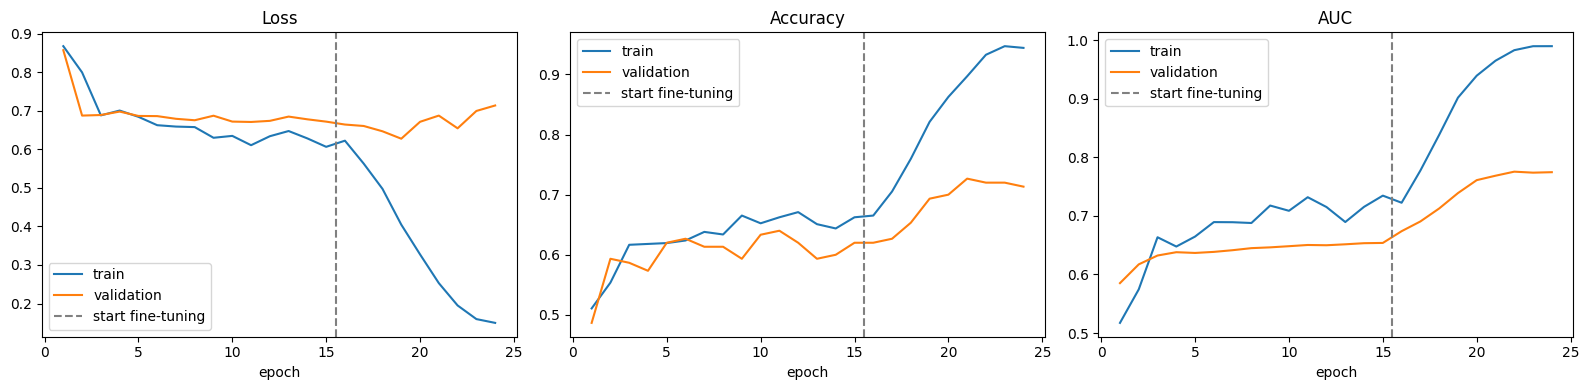

Best validation loss 0.6273 at epoch 19 (finetune) | val acc 0.6933 | val AUC 0.7388
Model saved to: /content/drive/MyDrive/Dataset/models/final/resnet50_correct_vs_wrong.keras


In [ ]:
# Join both stages into one history
history_all = {k: history_head.history[k] + history_fine.history[k] for k in history_head.history}
hist_df = pd.DataFrame(history_all)
hist_df.insert(0, "epoch", range(1, len(hist_df) + 1))
hist_df.insert(1, "stage", ["head"] * len(history_head.history["loss"]) + ["finetune"] * len(history_fine.history["loss"]))
hist_df.to_csv(METRICS_DIR / "resnet50_training_history.csv", index=False)

split_at = len(history_head.history["loss"]) + 0.5      # boundary between stage 1 and stage 2
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (key, title) in zip(axes, [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]):
    ax.plot(hist_df["epoch"], hist_df[key], label="train")
    ax.plot(hist_df["epoch"], hist_df[f"val_{key}"], label="validation")
    ax.axvline(split_at, color="gray", linestyle="--", label="start fine-tuning")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_training_curves.png", dpi=150)
plt.show()

best_row = hist_df.loc[hist_df["val_loss"].idxmin()]
print(f"Best validation loss {best_row['val_loss']:.4f} at epoch {int(best_row['epoch'])} "
      f"({best_row['stage']}) | val acc {best_row['val_accuracy']:.4f} | val AUC {best_row['val_auc']:.4f}")

model.save(FINAL_MODEL_DIR / "resnet50_correct_vs_wrong.keras")
print("Model saved to:", FINAL_MODEL_DIR / "resnet50_correct_vs_wrong.keras")

## 10. Model evaluation

Paste these cells below your last cell. They use `model`, `train_ds`, `val_ds`, `test_ds`, `test_df`, `CLASS_NAMES`, `METRICS_DIR`, `PLOTS_DIR` and `load_and_binarize` from the earlier cells.

**Positive class = class 1 = `Wrong`.** Precision, recall and F1 below are for detecting `Wrong` unless a row says macro or weighted.

In [ ]:
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay,
)

print("Positive class (label 1):", CLASS_NAMES[1])

def predict_dataset(ds):
    """Returns (true labels, predicted probability of class 1) in the same order, for any dataset."""
    labels, probs = [], []
    for x, y in ds:
        probs.append(np.asarray(model.predict_on_batch(x)).ravel())
        labels.append(y.numpy())
    return np.concatenate(labels), np.concatenate(probs)

def compute_metrics(y_true, probs, thr=0.5):
    y_pred = (probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold":         float(thr),
        "samples":           int(len(y_true)),
        "accuracy":          float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "precision":         float(precision_score(y_true, y_pred, zero_division=0)),
        "recall":            float(recall_score(y_true, y_pred, zero_division=0)),
        "specificity":       float(tn / (tn + fp)) if (tn + fp) else 0.0,
        "f1":                float(f1_score(y_true, y_pred, zero_division=0)),
        "f1_macro":          float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_weighted":       float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "roc_auc":           float(roc_auc_score(y_true, probs)),
        "pr_auc":            float(average_precision_score(y_true, probs)),
        "mcc":               float(matthews_corrcoef(y_true, y_pred)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

Positive class (label 1): Wrong


### Train vs validation vs test

If train is much better than validation/test, the model is overfitting.

In [ ]:
raw, results = {}, {}
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    y_t, p = predict_dataset(ds)
    raw[name] = (y_t, p)
    results[name] = compute_metrics(y_t, p, thr=0.5)

summary_cols = ["samples", "accuracy", "balanced_accuracy", "precision", "recall",
                "specificity", "f1", "f1_macro", "f1_weighted", "roc_auc", "pr_auc", "mcc"]
summary = pd.DataFrame(results).T[summary_cols]
summary["samples"] = summary["samples"].astype(int)
display(summary.round(4))
summary.to_csv(METRICS_DIR / "resnet50_metrics_all_splits.csv")

,samples,accuracy,balanced_accuracy,precision,recall,specificity,f1,f1_macro,f1_weighted,roc_auc,pr_auc,mcc
train,699,0.8941,0.8973,0.9361,0.8686,0.9260,0.9011,0.8936,0.8944,0.9647,0.9732,0.7901
val,150,0.6933,0.6984,0.7606,0.6506,0.7463,0.7013,0.6931,0.6940,0.7389,0.8006,0.3952
test,150,0.7267,0.7271,0.7692,0.7229,0.7313,0.7453,0.7252,0.7273,0.7873,0.7927,0.4520


### Test set: full classification report (threshold 0.5)

In [ ]:
y_true, probs = raw["test"]
y_pred = (probs >= 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

m = results["test"]
print(f"Accuracy          : {m['accuracy']:.4f}")
print(f"Precision ({CLASS_NAMES[1]}) : {m['precision']:.4f}")
print(f"Recall    ({CLASS_NAMES[1]}) : {m['recall']:.4f}")
print(f"F1-score  ({CLASS_NAMES[1]}) : {m['f1']:.4f}")
print(f"Macro F1          : {m['f1_macro']:.4f}")
print(f"ROC-AUC           : {m['roc_auc']:.4f}")
print(f"PR-AUC            : {m['pr_auc']:.4f}")
print(f"MCC               : {m['mcc']:.4f}")
print(f"TN={m['tn']}  FP={m['fp']}  FN={m['fn']}  TP={m['tp']}")

              precision    recall  f1-score   support

     Correct     0.6806    0.7313    0.7050        67
       Wrong     0.7692    0.7229    0.7453        83

    accuracy                         0.7267       150
   macro avg     0.7249    0.7271    0.7252       150
weighted avg     0.7296    0.7267    0.7273       150

Accuracy          : 0.7267
Precision (Wrong) : 0.7692
Recall    (Wrong) : 0.7229
F1-score  (Wrong) : 0.7453
Macro F1          : 0.7252
ROC-AUC           : 0.7873
PR-AUC            : 0.7927
MCC               : 0.4520
TN=49  FP=18  FN=23  TP=60


### Confusion matrix

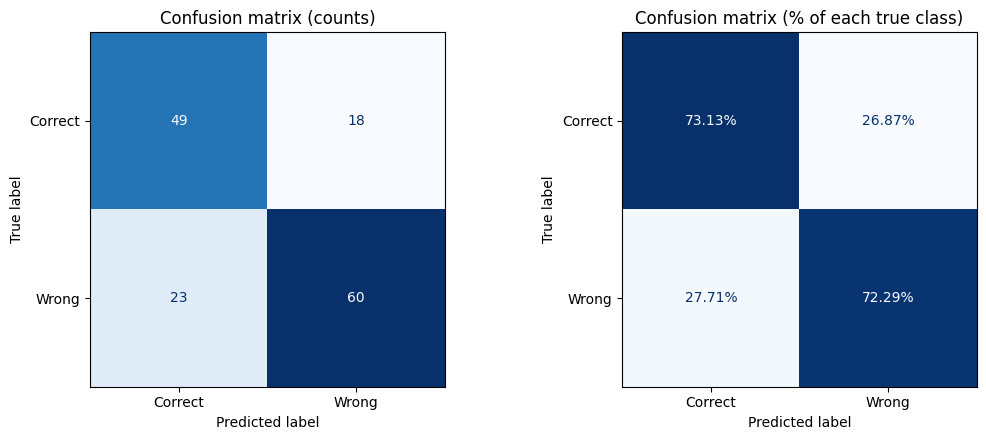

In [ ]:
cm      = confusion_matrix(y_true, y_pred, labels=[0, 1])
cm_norm = confusion_matrix(y_true, y_pred, labels=[0, 1], normalize="true")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_NAMES).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Confusion matrix (% of each true class)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_confusion_matrix.png", dpi=150)
plt.show()

### ROC curve, Precision-Recall curve and probability distribution

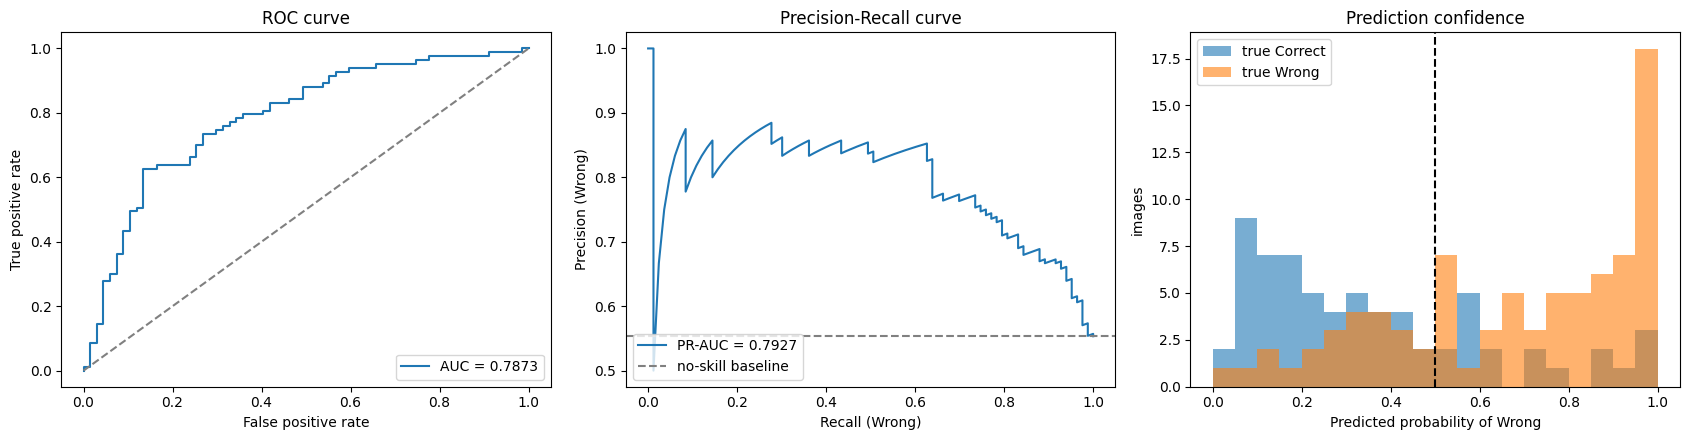

In [ ]:
fpr, tpr, _        = roc_curve(y_true, probs)
prec, rec, _       = precision_recall_curve(y_true, probs)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].plot(fpr, tpr, label=f"AUC = {m['roc_auc']:.4f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve"); ax[0].legend(loc="lower right")

ax[1].plot(rec, prec, label=f"PR-AUC = {m['pr_auc']:.4f}")
ax[1].axhline(y_true.mean(), linestyle="--", color="gray", label="no-skill baseline")
ax[1].set_xlabel(f"Recall ({CLASS_NAMES[1]})"); ax[1].set_ylabel(f"Precision ({CLASS_NAMES[1]})")
ax[1].set_title("Precision-Recall curve"); ax[1].legend(loc="lower left")

ax[2].hist(probs[y_true == 0], bins=20, range=(0, 1), alpha=0.6, label=f"true {CLASS_NAMES[0]}")
ax[2].hist(probs[y_true == 1], bins=20, range=(0, 1), alpha=0.6, label=f"true {CLASS_NAMES[1]}")
ax[2].axvline(0.5, color="black", linestyle="--")
ax[2].set_xlabel(f"Predicted probability of {CLASS_NAMES[1]}"); ax[2].set_ylabel("images")
ax[2].set_title("Prediction confidence"); ax[2].legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_roc_pr_distribution.png", dpi=150)
plt.show()

### Select the optimal classification threshold (chosen on the validation set, applied once to the test set)

0.5 is only the default. The threshold is picked using **validation** data so the test set stays an honest final check.

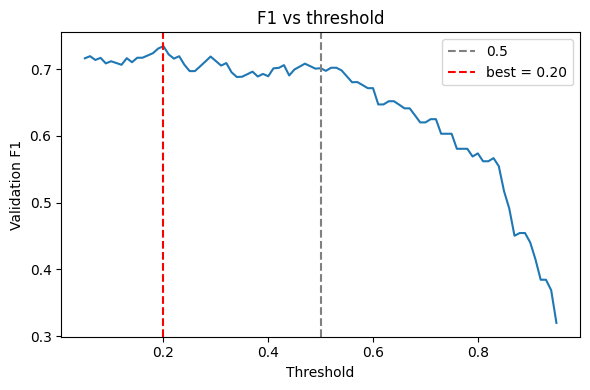

,threshold,accuracy,precision,recall,f1,f1_macro,mcc,tn,fp,fn,tp
test @ 0.50,0.5,0.7267,0.7692,0.7229,0.7453,0.7252,0.4520,49,18,23,60
test @ 0.20,0.2,0.6867,0.6500,0.9398,0.7685,0.6420,0.3889,25,42,5,78


In [ ]:
y_val, p_val = raw["val"]
thresholds = np.linspace(0.05, 0.95, 91)
val_f1 = np.array([f1_score(y_val, (p_val >= t).astype(int), zero_division=0) for t in thresholds])
best_thr = float(thresholds[int(np.argmax(val_f1))])

plt.figure(figsize=(6, 4))
plt.plot(thresholds, val_f1)
plt.axvline(0.5, color="gray", linestyle="--", label="0.5")
plt.axvline(best_thr, color="red", linestyle="--", label=f"best = {best_thr:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Validation F1"); plt.title("F1 vs threshold"); plt.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_f1_vs_threshold.png", dpi=150)
plt.show()

test_best = compute_metrics(y_true, probs, thr=best_thr)
cmp_cols = ["threshold", "accuracy", "precision", "recall", "f1", "f1_macro", "mcc", "tn", "fp", "fn", "tp"]
cmp_df = pd.DataFrame({"test @ 0.50": results["test"], f"test @ {best_thr:.2f}": test_best}).T[cmp_cols]
cmp_df[["tn", "fp", "fn", "tp"]] = cmp_df[["tn", "fp", "fn", "tp"]].astype(int)
display(cmp_df.round(4))

### Inspect misclassified test images (most confident mistakes first)

These show what the model gets wrong, which is useful for error analysis in the report.

Misclassified test images: 41 of 150


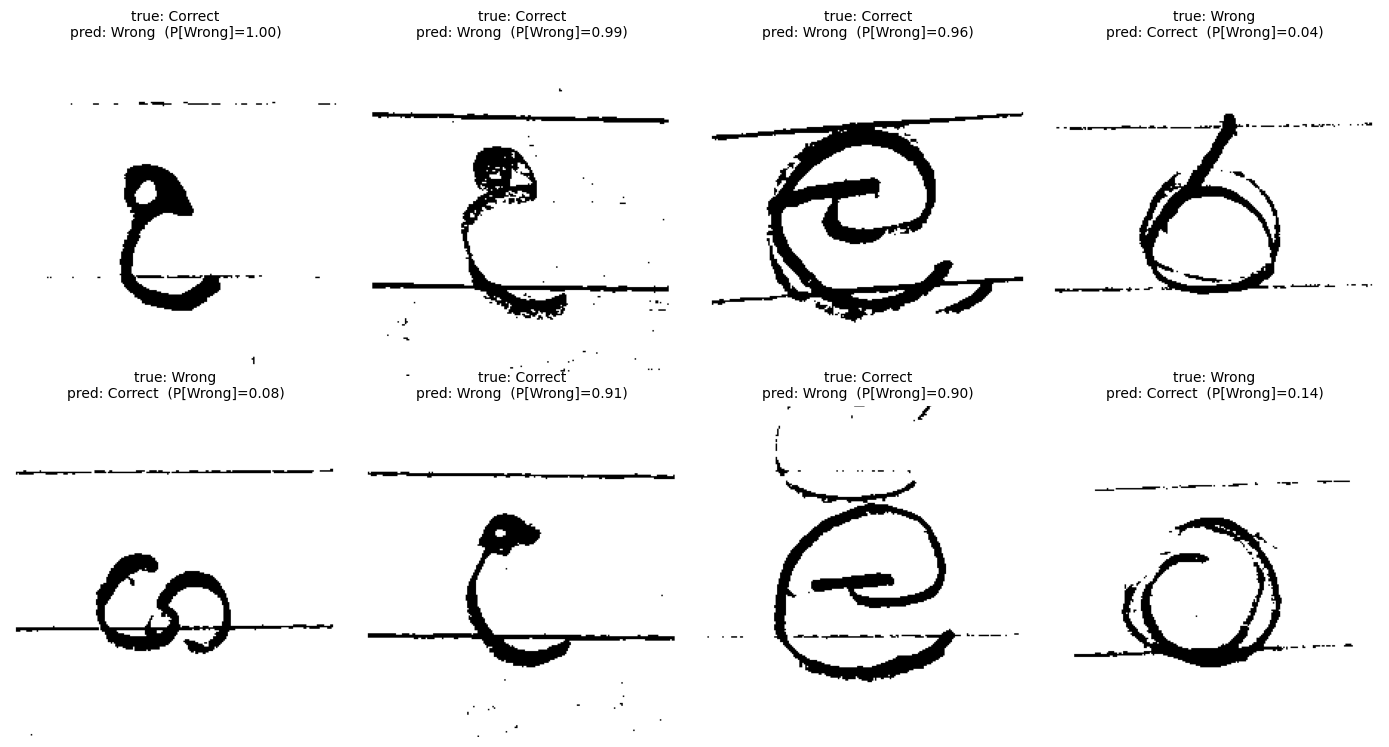

In [ ]:
assert np.array_equal(y_true, test_df["label"].values), "test_ds order does not match test_df"

wrong_idx = np.where(y_pred != y_true)[0]
print(f"Misclassified test images: {len(wrong_idx)} of {len(y_true)}")

if len(wrong_idx):
    confidence_error = np.abs(probs[wrong_idx] - y_true[wrong_idx])
    wrong_idx = wrong_idx[np.argsort(-confidence_error)]
    show = wrong_idx[:8]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        bw = load_and_binarize(test_df.iloc[i]["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]}  (P[{CLASS_NAMES[1]}]={probs[i]:.2f})",
                     fontsize=10)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "resnet50_misclassified.png", dpi=150)
    plt.show()

### Save the evaluation results and predictions

In [ ]:
with open(METRICS_DIR / "resnet50_test_metrics.json", "w") as f:
    json.dump({"test_threshold_0.5": results["test"],
               f"test_threshold_{best_thr:.2f}_chosen_on_val": test_best,
               "positive_class": CLASS_NAMES[1]}, f, indent=2)

pred_df = test_df.drop(columns=["md5"], errors="ignore").copy()
pred_df["prob_" + CLASS_NAMES[1]] = probs
pred_df["pred_label"] = y_pred
pred_df["pred_class"] = [CLASS_NAMES[i] for i in y_pred]
pred_df["is_correct"] = (y_pred == y_true)
pred_df.to_csv(METRICS_DIR / "resnet50_test_predictions.csv", index=False)

print("Saved to", METRICS_DIR)
print(" - resnet50_metrics_all_splits.csv")
print(" - resnet50_test_metrics.json")
print(" - resnet50_test_predictions.csv")
print("Plots saved to", PLOTS_DIR)

Saved to /content/drive/MyDrive/Dataset/results/metrics
 - resnet50_metrics_all_splits.csv
 - resnet50_test_metrics.json
 - resnet50_test_predictions.csv
Plots saved to /content/drive/MyDrive/Dataset/results/plots


### Download the trained model

In [ ]:
from google.colab import files
files.download(str(FINAL_MODEL_DIR / "resnet50_correct_vs_wrong.keras"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>